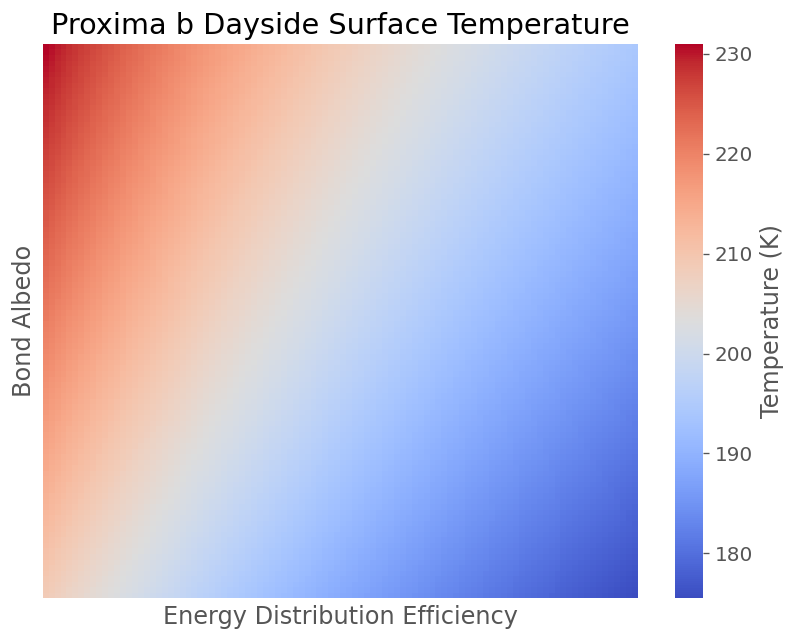

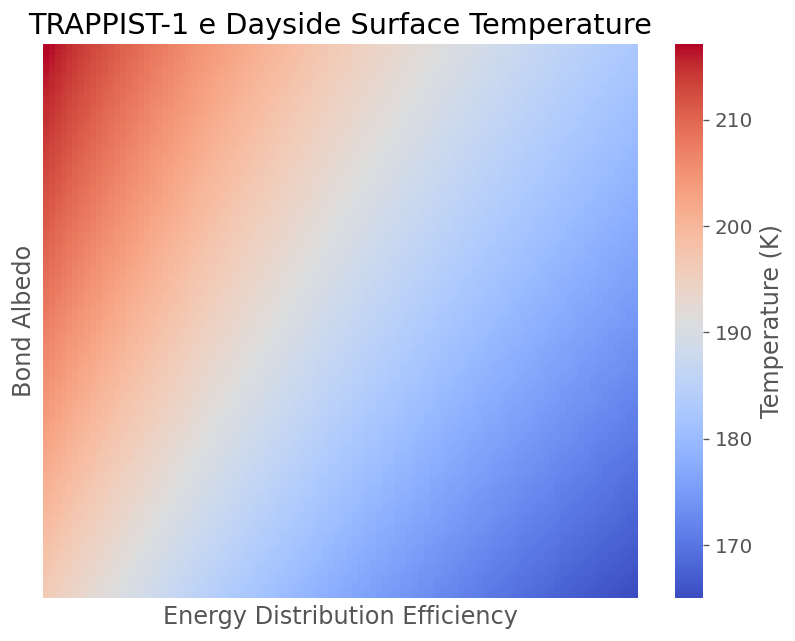

In [2]:
# First cell - Install required packages
!pip install numpy matplotlib seaborn

# Second cell - Import libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
plt.style.use('ggplot')  # Use a valid style from plt.style.available
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 12

# Function to calculate dayside temperature matrix
def calculate_surface_temperature_matrix(factors, temp_range, albedo_range, greenhouse_factor):
    """
    Calculate the dayside surface temperature for exoplanets based on given parameters.
    :param factors: Dict containing the flux, efficiency, etc.
    :param temp_range: Range of Bond albedos.
    :param albedo_range: Range of energy distribution efficiency values.
    :param greenhouse_factor: Greenhouse effect strength (epsilon).
    :return: Surface temperature matrix.
    """
    sigma = 5.67e-8  # Stefan-Boltzmann constant in W/m^2/K^4
    flux = factors['flux']  # Energy flux reaching the planet
    n_layers = factors['layers']  # Atmospheric layers

    # Dayside surface temperature matrix
    temperatures = []
    for albedo in albedo_range:
        row = []
        for efficiency in temp_range:
            temp_eq = (flux * (1 - albedo) / (4 * sigma))**0.25  # Equilibrium temp
            temp_dayside = temp_eq * (n_layers / efficiency * (1 - greenhouse_factor**2))**0.25
            row.append(temp_dayside)
        temperatures.append(row)
    return np.array(temperatures)

# Planet parameters
planets = {
    "Proxima b": {"flux": 881, "layers": 1, "greenhouse": 0.77},
    "TRAPPIST-1 e": {"flux": 688, "layers": 1, "greenhouse": 0.77}
}

# Create plots for each planet
temp_range = np.linspace(0.5, 1, 100)  # Energy distribution efficiency
albedo_range = np.linspace(0.1, 0.4, 100)  # Bond albedo

for planet, factors in planets.items():
    temp_matrix = calculate_surface_temperature_matrix(factors, temp_range, albedo_range, factors['greenhouse'])

    plt.figure(figsize=(8, 6))
    sns.heatmap(temp_matrix, cmap="coolwarm", xticklabels=False, yticklabels=False,
                cbar_kws={'label': 'Temperature (K)'})
    plt.title(f"{planet} Dayside Surface Temperature")
    plt.xlabel("Energy Distribution Efficiency")
    plt.ylabel("Bond Albedo")
    plt.show()


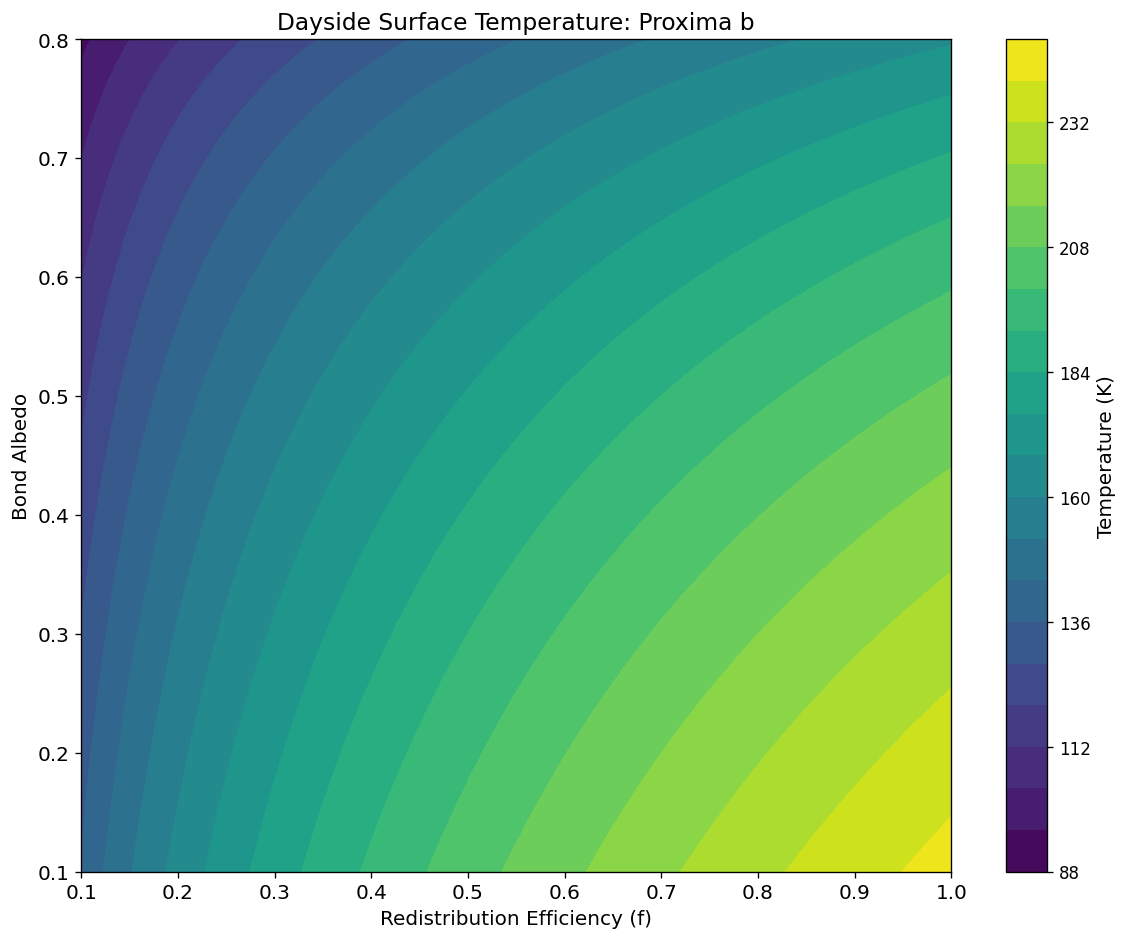

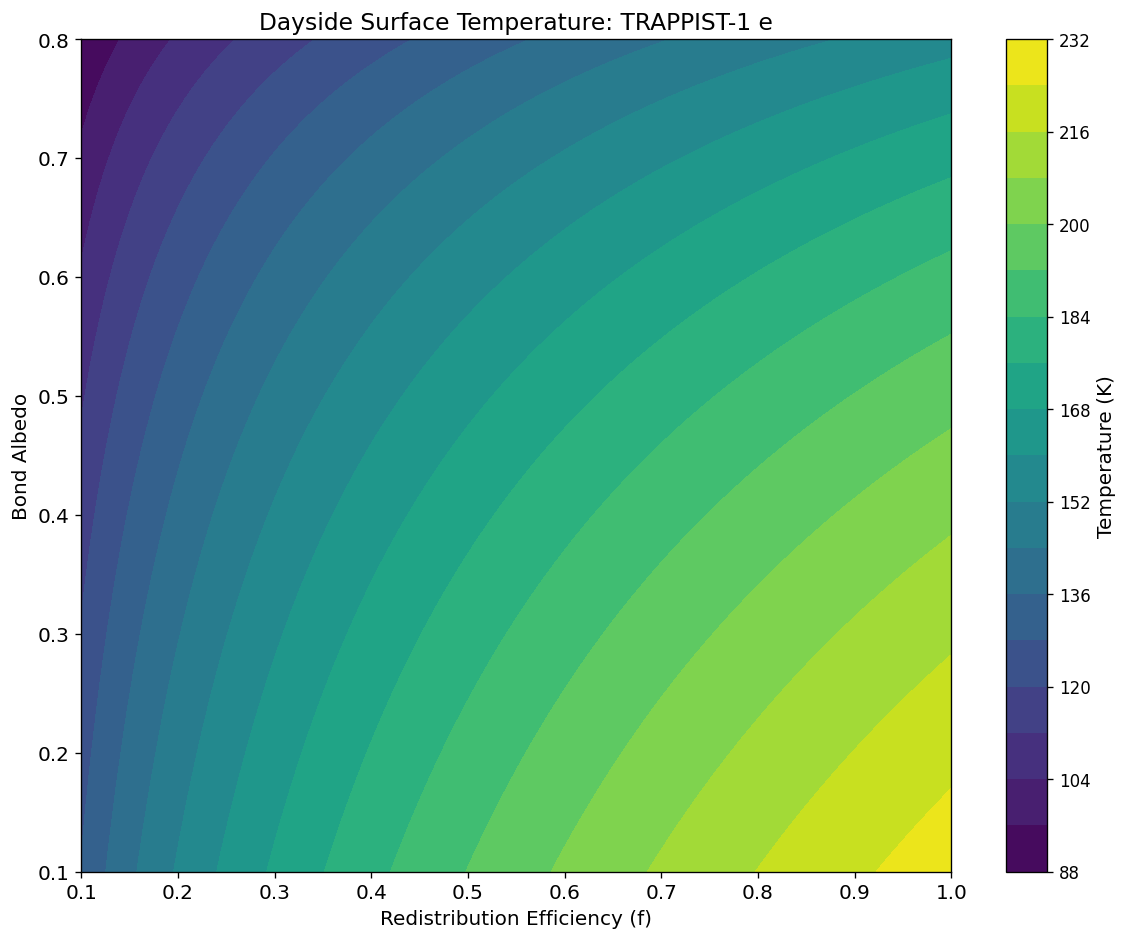

In [3]:
# First cell - Install required packages
!pip install numpy matplotlib seaborn

# Second cell - Import libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
plt.style.use('default')  # Use plain matplotlib style
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 12

# Function to calculate temperature
def calculate_temperature_matrix(factors, efficiency_range, albedo_range):
    """
    Calculate equilibrium temperature across energy efficiency and Bond albedo ranges.
    :param factors: Flux reaching the planet
    :param efficiency_range: Array of redistribution efficiencies
    :param albedo_range: Array of Bond albedos
    :return: Matrix of calculated temperatures
    """
    sigma = 5.67e-8  # Stefan-Boltzmann constant
    flux = factors['flux']  # Energy flux reaching the planet
    temperatures = []

    for albedo in albedo_range:
        row = []
        for efficiency in efficiency_range:
            temp = ((flux * (1 - albedo) / (4 * sigma)) * (efficiency))**0.25
            row.append(temp)
        temperatures.append(row)
    return np.array(temperatures)

# Planet properties
planet_properties = {
    "Proxima b": {"flux": 881},  # Flux in W/m^2
    "TRAPPIST-1 e": {"flux": 688}
}

# Define parameter ranges
efficiency_range = np.linspace(0.1, 1.0, 100)  # Redistribution efficiency (e.g., f in equations)
albedo_range = np.linspace(0.1, 0.8, 100)  # Bond albedo (0-1)

# Generate and plot results
for planet, factors in planet_properties.items():
    temp_matrix = calculate_temperature_matrix(factors, efficiency_range, albedo_range)

    # Create the plot
    plt.figure(figsize=(10, 8))
    plt.contourf(efficiency_range, albedo_range, temp_matrix, levels=20, cmap="viridis")
    cbar = plt.colorbar()
    cbar.set_label("Temperature (K)", fontsize=12)
    cbar.ax.tick_params(labelsize=10)

    # Add labels and title
    plt.xlabel("Redistribution Efficiency (f)", fontsize=12)
    plt.ylabel("Bond Albedo", fontsize=12)
    plt.title(f"Dayside Surface Temperature: {planet}", fontsize=14)
    plt.tight_layout()
    plt.show()


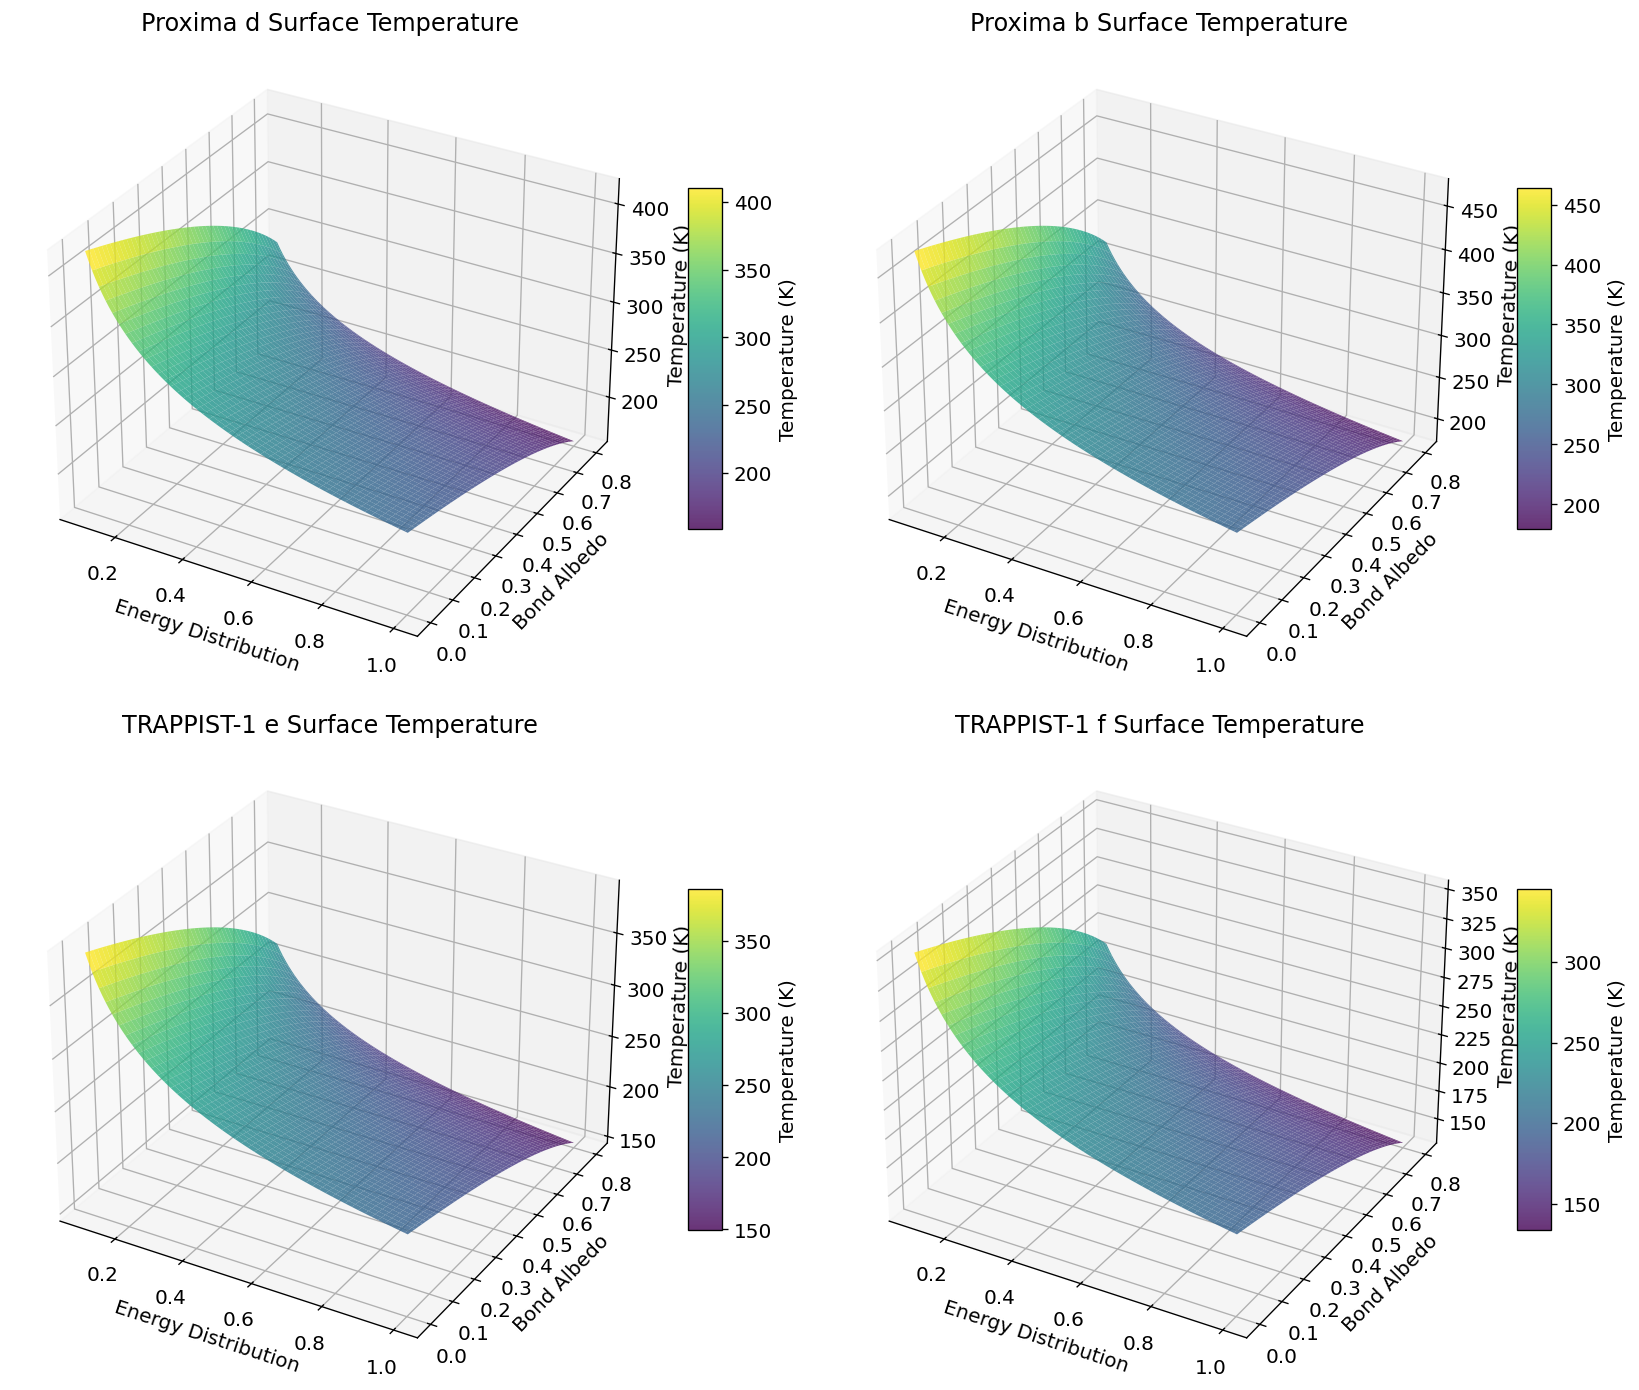

In [4]:
# Install necessary libraries (if not already installed)
!pip install numpy matplotlib

# Import libraries
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Function to calculate temperature
def calculate_temperature(factors, energy_distribution, albedo, greenhouse_effect):
    """
    Calculate dayside surface temperature.
    :param factors: Flux reaching the planet
    :param energy_distribution: Redistribution efficiency range
    :param albedo: Bond albedo range
    :param greenhouse_effect: Greenhouse effect range
    :return: Matrix of temperatures
    """
    sigma = 5.67e-8  # Stefan-Boltzmann constant
    temperatures = (factors['flux'] * (1 - albedo) * greenhouse_effect / (sigma * 4 * energy_distribution)) ** 0.25
    return temperatures

# Define ranges for parameters
energy_distribution = np.linspace(0.1, 1.0, 100)  # Redistribution efficiency
albedo = np.linspace(0.0, 0.8, 100)  # Bond albedo
greenhouse_effect = np.linspace(0.5, 1.0, 100)  # Greenhouse effect factor

# Create mesh grids for the parameters
X, Y = np.meshgrid(energy_distribution, albedo)

# Properties for planets
planet_properties = {
    "Proxima d": {"flux": 881},
    "Proxima b": {"flux": 1440},
    "TRAPPIST-1 e": {"flux": 688},
    "TRAPPIST-1 f": {"flux": 440},
}

# Loop through each planet and plot
fig, axes = plt.subplots(2, 2, subplot_kw={"projection": "3d"}, figsize=(14, 12))
axes = axes.flatten()

for idx, (planet, properties) in enumerate(planet_properties.items()):
    # Calculate temperatures
    Z = calculate_temperature(properties, X, Y, greenhouse_effect=0.8)  # Example greenhouse effect

    # Plot 3D surface
    ax = axes[idx]
    surf = ax.plot_surface(X, Y, Z, cmap="viridis", edgecolor="none", alpha=0.8)
    ax.set_xlabel("Energy Distribution")
    ax.set_ylabel("Bond Albedo")
    ax.set_zlabel("Temperature (K)")
    ax.set_title(f"{planet} Surface Temperature")
    fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10, label="Temperature (K)")

plt.tight_layout()
plt.show()


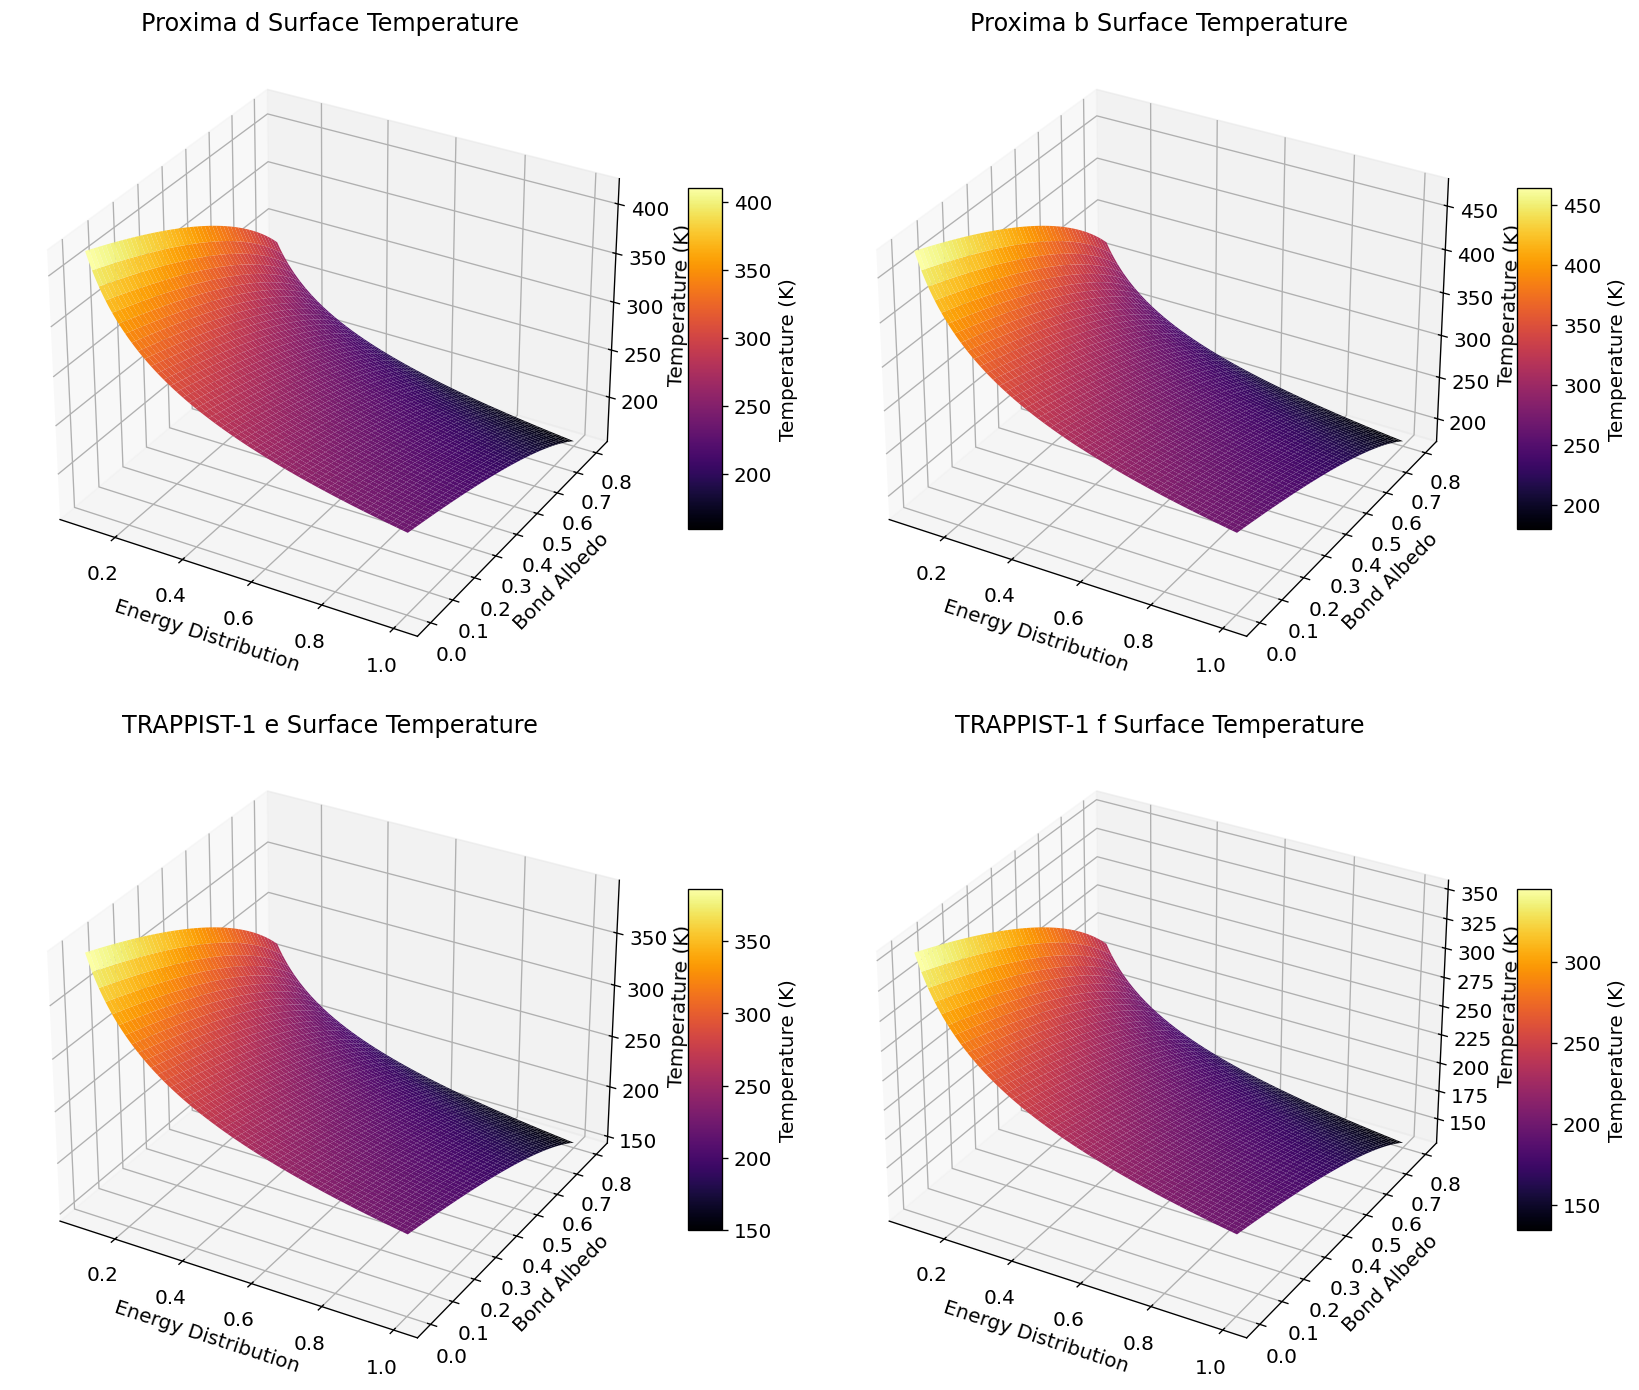

In [10]:
# Install necessary libraries (if not already installed)
!pip install numpy matplotlib

# Import libraries
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Function to calculate temperature
def calculate_temperature(factors, energy_distribution, albedo, greenhouse_effect):
    """
    Calculate dayside surface temperature.
    :param factors: Flux reaching the planet
    :param energy_distribution: Redistribution efficiency range
    :param albedo: Bond albedo range
    :param greenhouse_effect: Greenhouse effect range
    :return: Matrix of temperatures
    """
    sigma = 5.67e-8  # Stefan-Boltzmann constant
    temperatures = (factors['flux'] * (1 - albedo) * greenhouse_effect / (sigma * 4 * energy_distribution)) ** 0.25
    return temperatures

# Define ranges for parameters
energy_distribution = np.linspace(0.1, 1.0, 300)  # Redistribution efficiency with more points for smoothness
albedo = np.linspace(0.0, 0.8, 300)  # Bond albedo with more points for smoothness
greenhouse_effect = np.linspace(0.5, 1.0, 300)  # Greenhouse effect factor

# Create mesh grids for the parameters
X, Y = np.meshgrid(energy_distribution, albedo)

# Properties for planets
planet_properties = {
    "Proxima d": {"flux": 881},
    "Proxima b": {"flux": 1440},
    "TRAPPIST-1 e": {"flux": 688},
    "TRAPPIST-1 f": {"flux": 440},
}

# Loop through each planet and plot
fig, axes = plt.subplots(2, 2, subplot_kw={"projection": "3d"}, figsize=(14, 12))
axes = axes.flatten()

for idx, (planet, properties) in enumerate(planet_properties.items()):
    # Calculate temperatures
    Z = calculate_temperature(properties, X, Y, greenhouse_effect=0.8)  # Example greenhouse effect

    # Plot 3D surface with adjusted settings for better color gradients and smoothness
    ax = axes[idx]
    surf = ax.plot_surface(X, Y, Z, cmap="inferno", edgecolor="none", alpha=1.0)
    ax.set_xlabel("Energy Distribution")
    ax.set_ylabel("Bond Albedo")
    ax.set_zlabel("Temperature (K)")
    ax.set_title(f"{planet} Surface Temperature")

    # Add color bar for the temperature scale
    fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10, label="Temperature (K)")

# Adjust layout and display
plt.tight_layout()
plt.show()


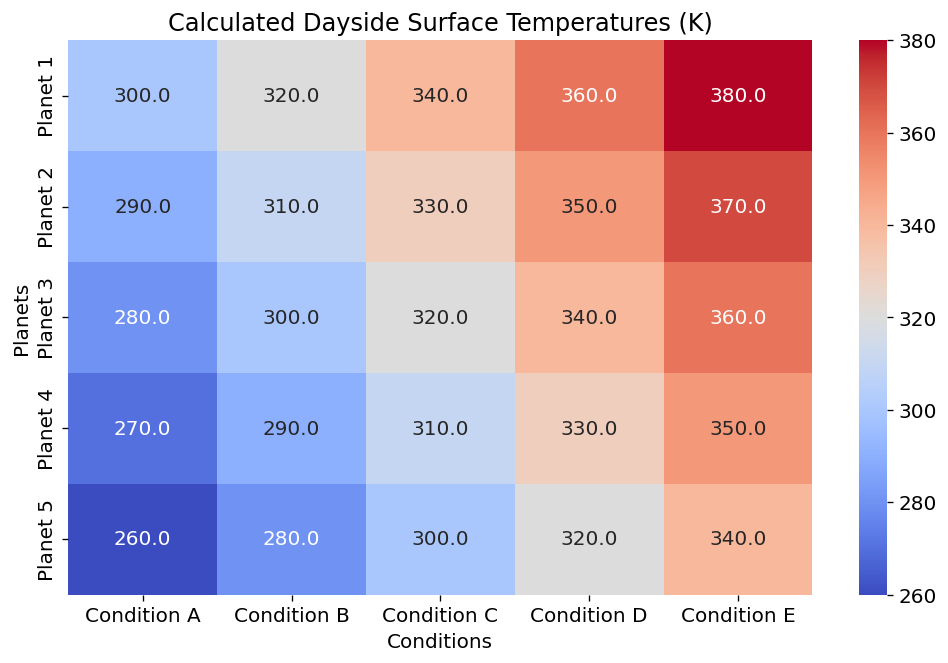

In [17]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define the temperature data matrix (example data, replace with actual values from the paper)
# Assuming we have temperatures for 5 planets across different conditions
temperatures = np.array([
    [300, 320, 340, 360, 380],  # Planet 1
    [290, 310, 330, 350, 370],  # Planet 2
    [280, 300, 320, 340, 360],  # Planet 3
    [270, 290, 310, 330, 350],  # Planet 4
    [260, 280, 300, 320, 340]   # Planet 5
])

# Define labels for the axes
planets = ['Planet 1', 'Planet 2', 'Planet 3', 'Planet 4', 'Planet 5']
conditions = ['Condition A', 'Condition B', 'Condition C', 'Condition D', 'Condition E']

# Create a heatmap using seaborn
plt.figure(figsize=(10, 6))
sns.heatmap(temperatures, annot=True, fmt=".1f", cmap='coolwarm', xticklabels=conditions, yticklabels=planets)

# Adding titles and labels
plt.title('Calculated Dayside Surface Temperatures (K)')
plt.xlabel('Conditions')
plt.ylabel('Planets')

# Show plot
plt.show()

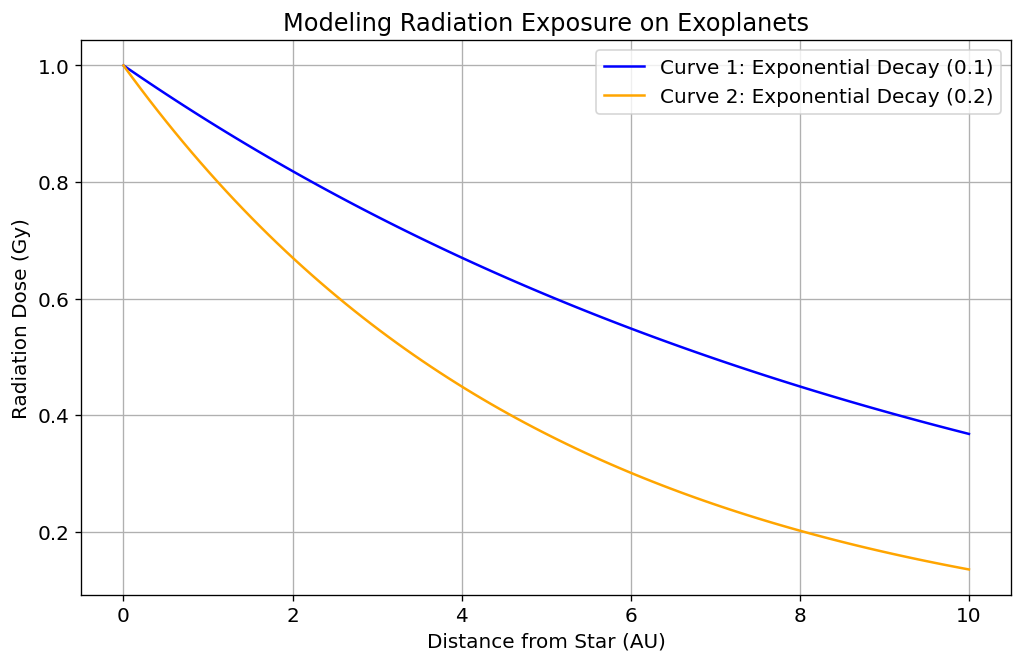

In [19]:
# Import necessary libraries
import numpy as np
import matplotlib.pyplot as plt

# Define parameters for the model (these should be adjusted based on the paper's specifics)
x = np.linspace(0, 10, 100)  # Example x values, adjust according to your needs
y1 = np.exp(-0.1 * x)  # Example function for one curve
y2 = np.exp(-0.2 * x)  # Example function for another curve

# Create the plot
plt.figure(figsize=(10, 6))

# Plotting the curves
plt.plot(x, y1, label='Curve 1: Exponential Decay (0.1)', color='blue')
plt.plot(x, y2, label='Curve 2: Exponential Decay (0.2)', color='orange')

# Adding titles and labels
plt.title('Modeling Radiation Exposure on Exoplanets')
plt.xlabel('Distance from Star (AU)')
plt.ylabel('Radiation Dose (Gy)')
plt.legend()
plt.grid(True)

# Show plot
plt.show()